In [1]:
import numpy as np

from NbodyIMRI import tools, particles, simulator, reader
from NbodyIMRI import units as u
from NbodyIMRI import distributionfunctions as DF
import NbodyIMRI

import h5py
import copy

In [2]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset, zoomed_inset_axes
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
# Use TeX
from matplotlib import rc
from matplotlib import ticker
rc('text', usetex=True)
rc('font', family='serif')


#----- MATPLOTLIB paramaters ---------
mpl.rcParams.update({'font.size': 16,'font.family':'serif'})

mpl.rcParams['axes.labelsize'] = 16
mpl.rcParams['axes.titlesize'] = 16

mpl.rcParams['xtick.labelsize'] = 16
mpl.rcParams['ytick.labelsize'] = 16

mpl.rcParams['xtick.major.size'] = 7
mpl.rcParams['xtick.major.width'] = 1

mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.minor.width'] = 1

mpl.rcParams['ytick.major.size'] = 7
mpl.rcParams['ytick.major.width'] = 1

mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.minor.width'] = 1

mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['savefig.dpi'] = 300

mpl.rcParams['figure.autolayout'] = False
#--------------------------------------




In [3]:
palette=["green", "#206AA3","#461220"] 
palette_shades=[ "#BEDFBF", "#88BEE7","#D96D8A"]

In [4]:
#some constants

G_N = 6.674e-11  #SI: N*m^2/kg^2
rho_eq = 1512.0*u.Msun/u.pc**3 

### Define the parameters for the three systems

In [5]:
XTE_dict={}
A0620_dict={}
NM_dict={}

dic_list=[XTE_dict,A0620_dict, NM_dict]

In [6]:
XTE_dict["name"]= "System A"
XTE_dict["color"]= palette[0]
XTE_dict["shade"]= palette_shades[0]
XTE_dict["linestyle"]='-'

XTE_dict["M_1"] = 7.46*u.Msun
XTE_dict["M_2"] = 0.2*u.Msun
XTE_dict["M2_err"] = 0.06*u.Msun

XTE_dict["q"] = 0.024
XTE_dict["q_err"] = 0.009

XTE_dict["r_orb"]= 5.72e-8*u.pc

XTE_dict["e_i"]  = 0.0

XTE_dict["r_star"]= 7.6e-9*u.pc

XTE_dict["rho_bkg"] = 0.34*u.GeV/u.cm**3

XTE_dict["dTobs"]=1.9
XTE_dict["dTerr"]=0.57

XTE_dict["K"]=708.8*u.km/u.s
XTE_dict["i"]=73.5 #degrees

XTE_dict["v_orb_2"]=XTE_dict["K"]/np.sin(np.radians(XTE_dict["i"]))


XTE_dict["gamma_ChanLee"]=1.85
XTE_dict["rho_ChanLee"]=1.60e-11*u.g/u.cm**3


In [7]:
A0620_dict["name"]= "System B"
A0620_dict["color"]= palette[1]
A0620_dict["shade"]= palette_shades[1]
A0620_dict["linestyle"]='--'

A0620_dict["M_1"] = 6.6*u.Msun
A0620_dict["M_2"] = 0.4*u.Msun
A0620_dict["M2_err"] = 0.01*u.Msun

A0620_dict["q"] = 0.060
A0620_dict["q_err"] = 0.004

A0620_dict["r_orb"]= 8.55e-8*u.pc


A0620_dict["e_i"]  = 0.0

A0620_dict["r_star"]= 1.5e-8*u.pc

A0620_dict["rho_bkg"] = 0.29*u.GeV/u.cm**3

A0620_dict["dTobs"]=0.6
A0620_dict["dTerr"]=0.08

A0620_dict["K"]=435.4*u.km/u.s
A0620_dict["i"]=51.0 #degrees

A0620_dict["v_orb_2"]=A0620_dict["K"]/np.sin(np.radians(A0620_dict["i"]))

A0620_dict["gamma_ChanLee"]=1.71
A0620_dict["rho_ChanLee"]=7.65e-13*u.g/u.cm**3


In [8]:
NM_dict["name"]= "System C"
NM_dict["color"]= palette[2]
NM_dict["shade"]= palette_shades[2]
NM_dict["linestyle"]=':'

NM_dict["M_1"] = 11*u.Msun
NM_dict["M_2"] = 0.89*u.Msun
NM_dict["M2_err"] = 0.18*u.Msun

NM_dict["q"] = 0.079
NM_dict["q_err"] = 0.007

NM_dict["r_orb"]= 1.238e-7*u.pc

NM_dict["e_i"]  = 0.0

NM_dict["r_star"]= 2.4e-8*u.pc

NM_dict["rho_bkg"] = 0.41*u.GeV/u.cm**3

NM_dict["dTobs"]=20.7
NM_dict["dTerr"]=12.7

NM_dict["K"]=406.8*u.km/u.s
NM_dict["i"]=43.2 #degrees

NM_dict["v_orb_2"]=NM_dict["K"]/np.sin(np.radians(NM_dict["i"]))


In [9]:
for dic in dic_list:

    dic["a_i"]=dic["r_orb"]

    dic["T_orb"] =tools.calc_Torb(a_i = dic["a_i"], M_tot = dic["M_1"]+dic["M_2"])
    dic["v_orb"] =2*np.pi * dic["r_orb"]/dic["T_orb"]

### Compute the Chandrasekhar friction

In [10]:
def r_sp(gamma, dic):   
    '''
    gamma: spike index
    dic: dictionary
    returns: the spike radius (0.2 r_in)
    '''
    
    M_1=dic["M_1"]
    M_2=dic["M_2"]
    a=dic["a_i"]
    vorb=dic["v_orb"]     
    rho_bkg=dic["rho_bkg"]
    
    ga=gamma
    
    return 0.2*(2*M_1/rho_bkg*(3-ga)/4/np.pi)**(1./3.)

In [11]:
def compute_rho(r, gamma, dic):    
    ''' 
    r: radius
    gamma: spike index
    dic: dictionary
    returns: spike density at r
    '''
    
    M_1=dic["M_1"]
    M_2=dic["M_2"]
    a=dic["a_i"]
    vorb=dic["v_orb"]     
    rho_bkg=dic["rho_bkg"]
    
    ga=gamma
    
    r_sp= 0.2*(2*M_1/rho_bkg*(3-ga)/4/np.pi)**(1./3.)

    rho_6=rho_bkg*(1e-6*u.pc/r_sp)**(-ga)
    
    return rho_6*(r/(1e-6*u.pc))**(-ga)

In [12]:
def compute_dTdt_CH(rho, dic):
    ''' 
    rho: spike density at orbital radius
    dic: dictionary
    returns: Pdot from Chandrasekhar expression
    '''
    
    M_1=dic["M_1"]
    M_2=dic["M_2"]
    a=dic["a_i"]
    vorb=dic["v_orb"] 
    
    Clog=np.log(np.sqrt(M_1/M_2))  #Coulomb log
    vfactor=1                      #fraction of particles slower than star (approximate to 1)

    dE= - 4*np.pi*G_N**2*M_2**2*rho*Clog*vfactor/vorb
    
    dT= 6*np.pi*a**(5./2.)/(M_2*M_1)/(G_N)**(3./2.)/(M_1+M_2)**(1./2.)*dE
    
    return dT
    

In [13]:
def compute_rho_CH(dic, dT):
    ''' 
    dT: Pdot 
    dic: dictionary
    returns: the density required to produce a variation Pdot, inverting the Chandrasekhar expression
    '''
    
    M_1=dic["M_1"]
    M_2=dic["M_2"]
    a=dic["a_i"]
    vorb=dic["v_orb"] 
    
    Clog=np.log(np.sqrt(M_1/M_2))
    vfactor=1

    den= -4*np.pi*G_N**2*M_2**2*Clog*vfactor/vorb*6*np.pi*a**(5./2.)/(M_2*M_1)/(G_N)**(3./2.)/(M_1+M_2)**(1./2.)
    
    rho= -dT/den
    
    return rho
    

I compute the density necessary to produce the observed period decay.

For systems A and B I compare to Chan and Lee results.

In [14]:
for dic in dic_list:
    
    dic["rho_CH"]=compute_rho_CH(dic, dic["dTobs"]/1000*u.s/u.yr) # 6GM/c^2
    
    print(f'For {dic["name"]} the CH infered density is: {dic["rho_CH"]/u.g*u.cm**3:.2e} g cm-3')
    
    if "gamma_ChanLee" in dic.keys():
    
        rho_Chan_Lee= compute_rho(dic["r_orb"], dic["gamma_ChanLee"], dic)
    
        #print(f'Using gamma = {dic["gamma_ChanLee"]} I infer rho= {rho_Chan_Lee/u.g*u.cm**3:.2e} g cm-3')
        print(f'Chan and Lee report {dic["rho_ChanLee"]/u.g*u.cm**3:.2e} g cm-3')
        print(f'The ratio of densities is: {dic["rho_ChanLee"]/dic["rho_CH"]:.2f} ')


For System A the CH infered density is: 1.45e-11 g cm-3
Chan and Lee report 1.60e-11 g cm-3
The ratio of densities is: 1.10 
For System B the CH infered density is: 7.16e-13 g cm-3
Chan and Lee report 7.65e-13 g cm-3
The ratio of densities is: 1.07 
For System C the CH infered density is: 1.15e-11 g cm-3


### Load $\dot{P}$ readings from simulations

In [15]:
gammalist=[1.90 , 1.95, 2.00 , 2.05, 2.10 , 2.15, 2.20, 2.25, 2.3, 2.35, 2.40, 2.45]

In [16]:
# Load simulation results
#data = np.load('XTE_dTdt.npz')
data = np.load('A_Pdot.npz')
XTE_dict["points"] = data['array1']
XTE_dict["means"] = data['array2']
XTE_dict["sigmas"] = data['array3']

data = np.load('B_Pdot.npz')
A0620_dict["points"] = data['array1']
A0620_dict["means"] = data['array2']
A0620_dict["sigmas"] = data['array3']

data = np.load('C_pdot.npz')
NM_dict["points"] = data['array1']
NM_dict["means"] = data['array2']
NM_dict["sigmas"] = data['array3']


/usr/local/lib/python3.9/site-packages/IPython/core/pylabtools.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


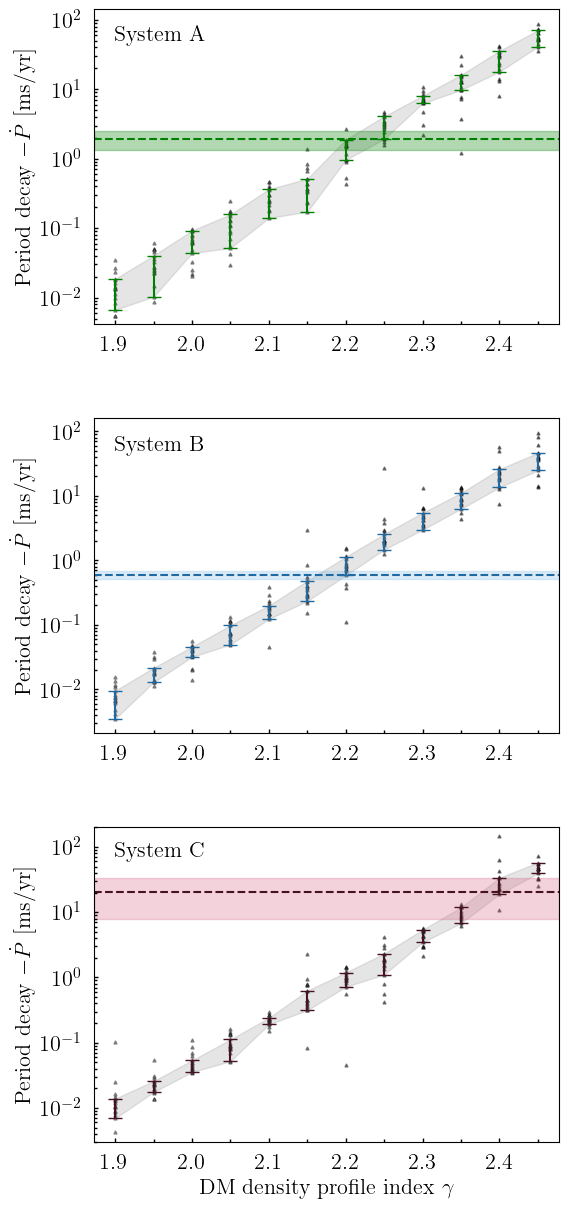

In [93]:

# Create figure with two side-by-side subplots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(6, 15),  # 12" width, 5" height
                               sharex=False,             # Share x-axis scale/labels
                               gridspec_kw={'hspace': 0.3},  # Reduce space between plots
                            dpi=100) 


cmap = plt.get_cmap('bone')
colors = cmap(np.linspace(0,1, len(gammalist)+2))


def plotstuff(ax, values, means, sigmas, dTobs, dTerr, color, shade):
    # Plot individual points
    for i, gamma in enumerate(gammalist):       
        mean=-means[i]
        sigma=sigmas[i]
        points= -values[i]

        ax.scatter(gamma*np.ones(len(points)), points, alpha=.5, s=4, marker="^", color=colors[-(i+2)], edgecolor='black')
        # Plot standard deviations as vertical error bars
        ax.errorbar(gamma, mean, yerr=sigma, fmt='none', ecolor=color, capsize=5)
       
    ax.fill_between(gammalist, y1=-(means-sigmas), y2=-(means+sigmas), color='gray',alpha=.2)   
    ax.axhline(dTobs, linestyle='--', color=color)
    ax.axhspan((dTobs-dTerr), (dTobs+dTerr) , alpha=0.3, color=shade)
    
    ax.set_yscale("log")
    
    
plotstuff(ax1, XTE_dict["points"], XTE_dict["means"], XTE_dict["sigmas"], XTE_dict["dTobs"], XTE_dict["dTerr"], XTE_dict["color"], XTE_dict["color"])
plotstuff(ax2, A0620_dict["points"], A0620_dict["means"], A0620_dict["sigmas"], A0620_dict["dTobs"], A0620_dict["dTerr"], A0620_dict["color"], A0620_dict["shade"])
plotstuff(ax3, NM_dict["points"], NM_dict["means"], NM_dict["sigmas"], NM_dict["dTobs"], NM_dict["dTerr"],NM_dict["color"],NM_dict["shade"])

ax1.set_ylabel(r" Period decay $-\dot{P}$ [ms/yr]")
ax2.set_ylabel(r" Period decay $-\dot{P}$ [ms/yr]")
ax3.set_ylabel(r" Period decay $-\dot{P}$ [ms/yr]")
ax3.set_xlabel(r'DM density profile index $\gamma$') 

ax1.tick_params(axis='both', which='both', direction='in', length=2, pad=8)
ax2.tick_params(axis='both', which='both', direction='in', length=2)
ax3.tick_params(axis='both', which='both', direction='in', length=2, pad=8)
ax1.tick_params(axis='both', which='major', direction='in', length=3)
ax2.tick_params(axis='both', which='major', direction='in', length=3, pad=8)
ax3.tick_params(axis='both', which='major', direction='in', length=3)

ax1.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax1.xaxis.set_minor_locator(plt.MultipleLocator(.05))
ax2.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax2.xaxis.set_minor_locator(plt.MultipleLocator(.05))
ax3.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax3.xaxis.set_minor_locator(plt.MultipleLocator(.05))

ax3.set_ylim(3e-3, 200)

ax1.text(1.9, 50, "System A", fontsize=16, color= "k")
ax2.text(1.9, 50, "System B", fontsize=16, color= "k")
ax3.text(1.9, 70, "System C", fontsize=16, color= "k")

#plt.savefig('../plots/dTdt_log_2.pdf',transparent=False,bbox_inches='tight')


plt.show()


### Find lower and upper $\gamma$ limits 

In [18]:
def find_intersection(x1,x2,y1,y2,y3):
    
    m=(y2-y1)/(x2-x1)
    
    x3=x1+(y3-y1)/m
    
    return x3

In [19]:
def find_log_intersection(x1,x2,y1,y2,y3):
    
    m=np.log10(y2/y1)/(x2-x1)
    
    x3=x1+np.log10(y3/y1)/m
    
    return x3

In [20]:
#From the plot above I read the gamma values between which I should interpolate

gmin=[[2.15,2.20], [2.15,2.20], [2.3, 2.35]]
gmax=[[2.25,2.30], [2.20,2.25], [2.4, 2.45]]

In [21]:
for i, dic in enumerate(dic_list):
    
    mean=dic["means"]
    sigma=dic["sigmas"]
    
    #find minimum
    
    g1=gmin[i][0]
    g2=gmin[i][1]
    
        
    ix1=gammalist.index(g1)
    ix2=gammalist.index(g2)
    
    y1=mean[ix1]-sigma[ix1]
    y2=mean[ix2]-sigma[ix2]
    
    y3=-dic["dTobs"]+dic["dTerr"]
    
          
    gamma_min=find_intersection(g1,g2,y1,y2,y3)   
    gamma_min_log=find_log_intersection(g1,g2,y1,y2,y3)  
    
    dic["g_min"]=gamma_min
    dic["g_min_log"]=gamma_min_log
    
    g1=gmax[i][0]
    g2=gmax[i][1]
    
    
    ix1=gammalist.index(g1)
    ix2=gammalist.index(g2)
    
    y1=mean[ix1]+sigma[ix1]
    y2=mean[ix2]+sigma[ix2]
    
    y3=-dic["dTobs"]-dic["dTerr"]
    
           
    gamma_max=find_intersection(g1,g2,y1,y2,y3)  
    gamma_max_log=find_log_intersection(g1,g2,y1,y2,y3)  
    
    dic["g_max"]=gamma_max
    dic["g_max_log"]=gamma_max_log
    
    

## Plot results

<ipython-input-118-b99a915c0500>:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../plots/Pdot_gamma.pdf',transparent=False,bbox_inches='tight')


<Figure size 3000x1800 with 0 Axes>

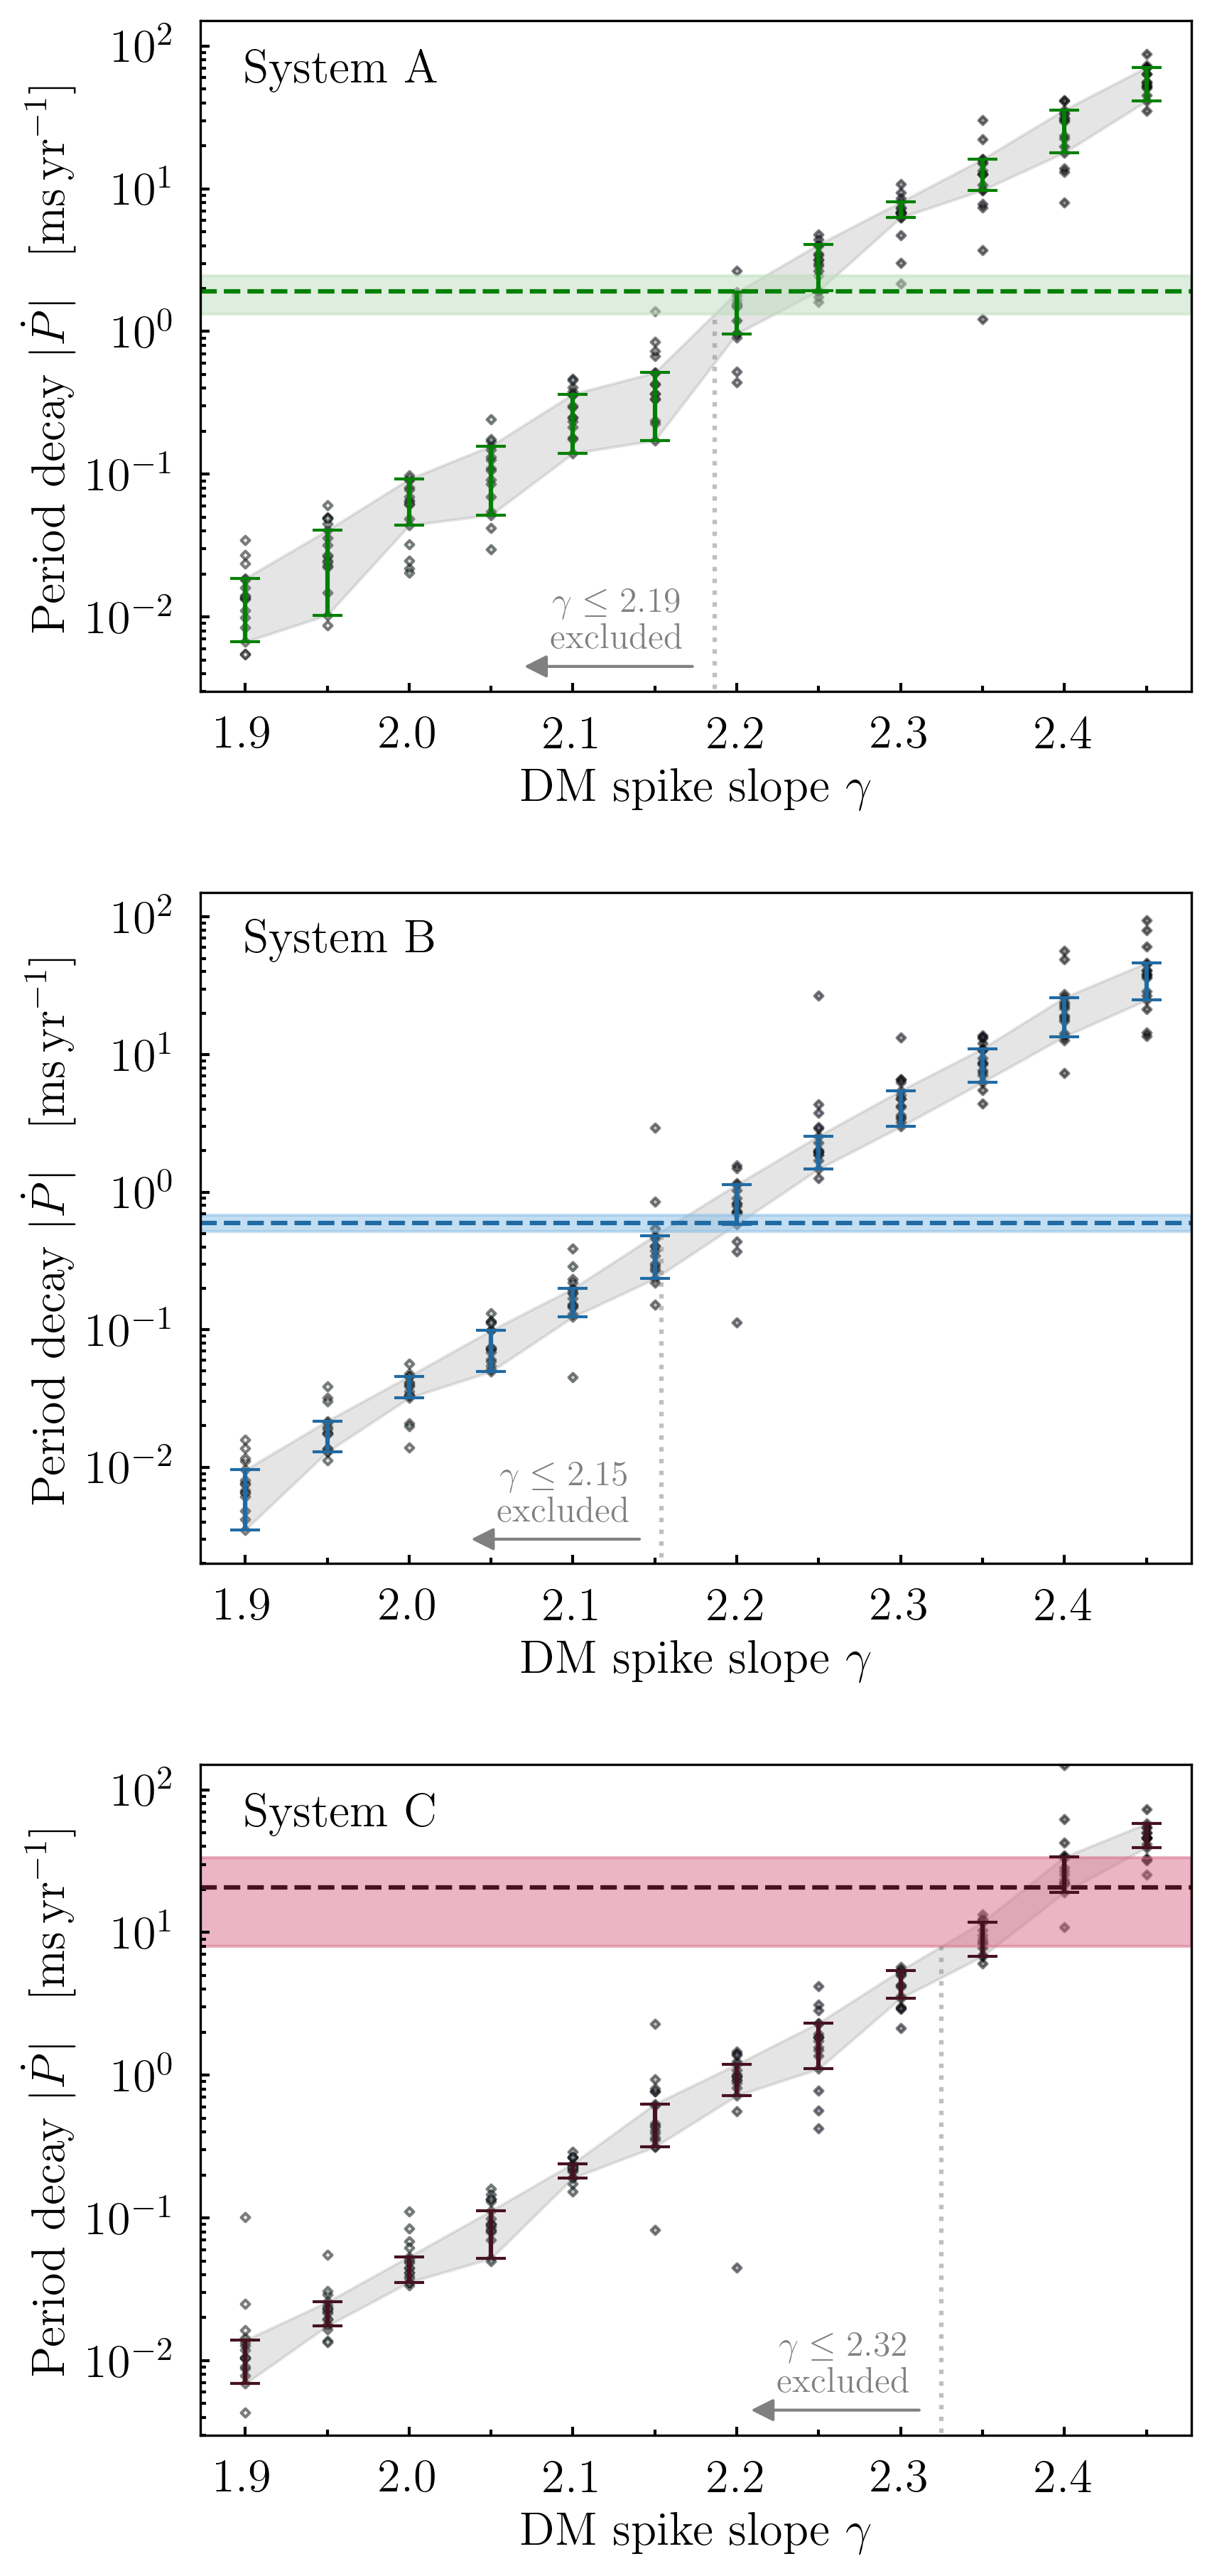

In [118]:
plt.figure(figsize=(10, 6))

# Create figure with two side-by-side subplots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(6, 15),  # 12" width, 5" height
                               sharex=False,             # Share x-axis scale/labels
                               gridspec_kw={'hspace': 0.3})  # Reduce space between plots



cmap = plt.get_cmap('bone')
colors = cmap(np.linspace(0,1, len(gammalist)+2))


def plotstuff(ax,dic):
    # Plot individual points
    
    values=dic["points"]
    means=dic["means"]
    sigmas=dic["sigmas"]
    dTobs=dic["dTobs"]
    dTerr=dic["dTerr"]
    color=dic["color"]
    shade=dic["shade"]
    
    for i, gamma in enumerate(gammalist):       
        mean=-means[i]
        sigma=sigmas[i]
        points= -values[i]

        ax.scatter(gamma*np.ones(len(points)), points, alpha=.5, s=4, marker="D", color=colors[-(i+2)], edgecolor='black')
        # Plot standard deviations as vertical error bars
        ax.errorbar(gamma, mean, yerr=sigma, fmt='none', ecolor=color, capsize=5)
       
    ax.fill_between(gammalist, y1=-(means-sigmas), y2=-(means+sigmas), color='gray',alpha=.2)   
    ax.axhline(dTobs, linestyle='--', color=color)
    ax.axhspan((dTobs-dTerr), (dTobs+dTerr) , alpha=0.5, color=shade)
    
    ax.vlines(dic["g_min_log"],1e-3, (dTobs-dTerr),  alpha=.5, color="gray", linestyle=":")
   
    ax.set_yscale("log")
    
    
plotstuff(ax1, XTE_dict)
plotstuff(ax2, A0620_dict)
plotstuff(ax3, NM_dict)


    
ax1.set_ylabel(r" Period decay $|\dot{P}|$ \, $[\mathrm{ms} \, \mathrm{yr}^{-1}]$")
ax2.set_ylabel(r" Period decay $|\dot{P}|$ \, $[\mathrm{ms} \, \mathrm{yr}^{-1}]$")
ax3.set_ylabel(r" Period decay $|\dot{P}|$ \, $[\mathrm{ms} \, \mathrm{yr}^{-1}]$")
ax1.set_xlabel(r'DM spike slope $\gamma$')
ax2.set_xlabel(r'DM spike slope $\gamma$') 
ax3.set_xlabel(r'DM spike slope $\gamma$') 


ax1.tick_params(axis='both', which='both', direction='in', length=2, pad=8)
ax2.tick_params(axis='both', which='both', direction='in', length=2)
ax3.tick_params(axis='both', which='both', direction='in', length=2, pad=8)
ax1.tick_params(axis='both', which='major', direction='in', length=3)
ax2.tick_params(axis='both', which='major', direction='in', length=3, pad=8)
ax3.tick_params(axis='both', which='major', direction='in', length=3)

ax1.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax1.xaxis.set_minor_locator(plt.MultipleLocator(.05))
ax2.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax2.xaxis.set_minor_locator(plt.MultipleLocator(.05))
ax3.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax3.xaxis.set_minor_locator(plt.MultipleLocator(.05))


ax1.set_ylim(3e-3, 150)
ax2.set_ylim(2e-3, 150)
ax3.set_ylim(3e-3, 150)

ax1.text(1.9, 55, "System A", fontsize=16, color= "k")
ax2.text(1.9, 55, "System B", fontsize=16, color= "k")
ax3.text(1.9, 55, "System C", fontsize=16, color= "k")



x1_arrow=XTE_dict["g_min_log"]
x2_arrow=A0620_dict["g_min_log"]
x3_arrow=NM_dict["g_min_log"]
      
ax1.annotate('', xy=(x1_arrow-.12, 1.5*3e-3), xytext=(x1_arrow-.01, 1.5*3e-3),arrowprops=dict(arrowstyle='-|>', alpha=1, color="gray", lw=1))
ax2.annotate('', xy=(x2_arrow-.12, 1.5*2e-3), xytext=(x2_arrow-.01, 1.5*2e-3),arrowprops=dict(arrowstyle='-|>', alpha=1, color="gray", lw=1))
ax3.annotate('', xy=(x3_arrow-.12, 1.5*3e-3), xytext=(x3_arrow-.01, 1.5*3e-3),arrowprops=dict(arrowstyle='-|>', alpha=1, color="gray", lw=1))

#ax1.text(x1_arrow-.1, 2*3e-3, "Excluded", fontsize=12, color= "gray")
#ax2.text(x2_arrow-.1, 2*2e-3, "Excluded", fontsize=12, color= "gray")
#ax3.text(x3_arrow-.1, 2*3e-3, "Excluded", fontsize=12, color= "gray")

ax1.text(x1_arrow - 0.06, 2*3e-3, f"$\gamma \leq {x1_arrow:.2f}$" +" \nexcluded", 
         fontsize=12, 
         color="gray", 
         ha='center'   # Horizontal alignment
        ) 

ax2.text(x2_arrow - 0.06, 2*2e-3, f"$\gamma \leq {x2_arrow:.2f}$" +" \nexcluded", 
         fontsize=12, 
         color="gray", 
         ha='center'   # Horizontal alignment
        ) 

ax3.text(x3_arrow - 0.06, 2*3e-3, f"$\gamma \leq {x3_arrow:.2f}$" +" \nexcluded", 
         fontsize=12, 
         color="gray", 
         ha='center'   # Horizontal alignment
        ) 


plt.savefig('../plots/Pdot_gamma.pdf',transparent=False,bbox_inches='tight')


plt.show()


In [68]:
def plot_excluded_range_semilogy(ax, start, end, cross_height_factor, y_m=None, spacing=0.2, **kwargs):
    """
    Plot crosses along the x-axis to indicate an excluded range for semilogy plots
    
    Parameters:
    ax: matplotlib axes object
    start: start of excluded range (x-coordinate)
    end: end of excluded range (x-coordinate)
    y_m: min y-position where crosses will be drawn (if None, uses bottom of plot)
    cross_height_factor: height of crosses as fraction of current y-range
    spacing: distance between crosses
    **kwargs: additional arguments for line properties (color, linewidth, etc.)
    """
    # Get current y-axis limits in log space
    y_min, y_max = ax.get_ylim()
    
    # Calculate appropriate y position if not specified
    if y_m is None:
        y_m = y_min  # Slightly above the bottom
    
    #Calulate y position of centre
    y_pos=y_m*np.sqrt(cross_height_factor)

    # Calculate cross positions
    x_positions = -np.arange(- end+ spacing/2, -start ,  spacing)
    
    # Create line segments for all crosses
    segments = []
    half_width = spacing * 0.45  # Width proportional to spacing
    
    for x in x_positions:
        # For log scale, we use multiplicative offsets for height
        y_bottom = y_m
        y_top = y_pos * np.sqrt(cross_height_factor)
        
        # First diagonal: from bottom-left to top-right
        segments.append([(x - half_width, y_bottom), 
                        (x + half_width, y_top)])
        # Second diagonal: from top-left to bottom-right
        segments.append([(x - half_width, y_top), 
                        (x + half_width, y_bottom)])
    
    # Create line collection
    lc = LineCollection(segments, **kwargs)
    ax.add_collection(lc)
    
    return y_pos


<ipython-input-69-5c18018b294f>:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../plots/Pdot_gamma_v2.pdf',transparent=False,bbox_inches='tight')


<Figure size 3000x1800 with 0 Axes>

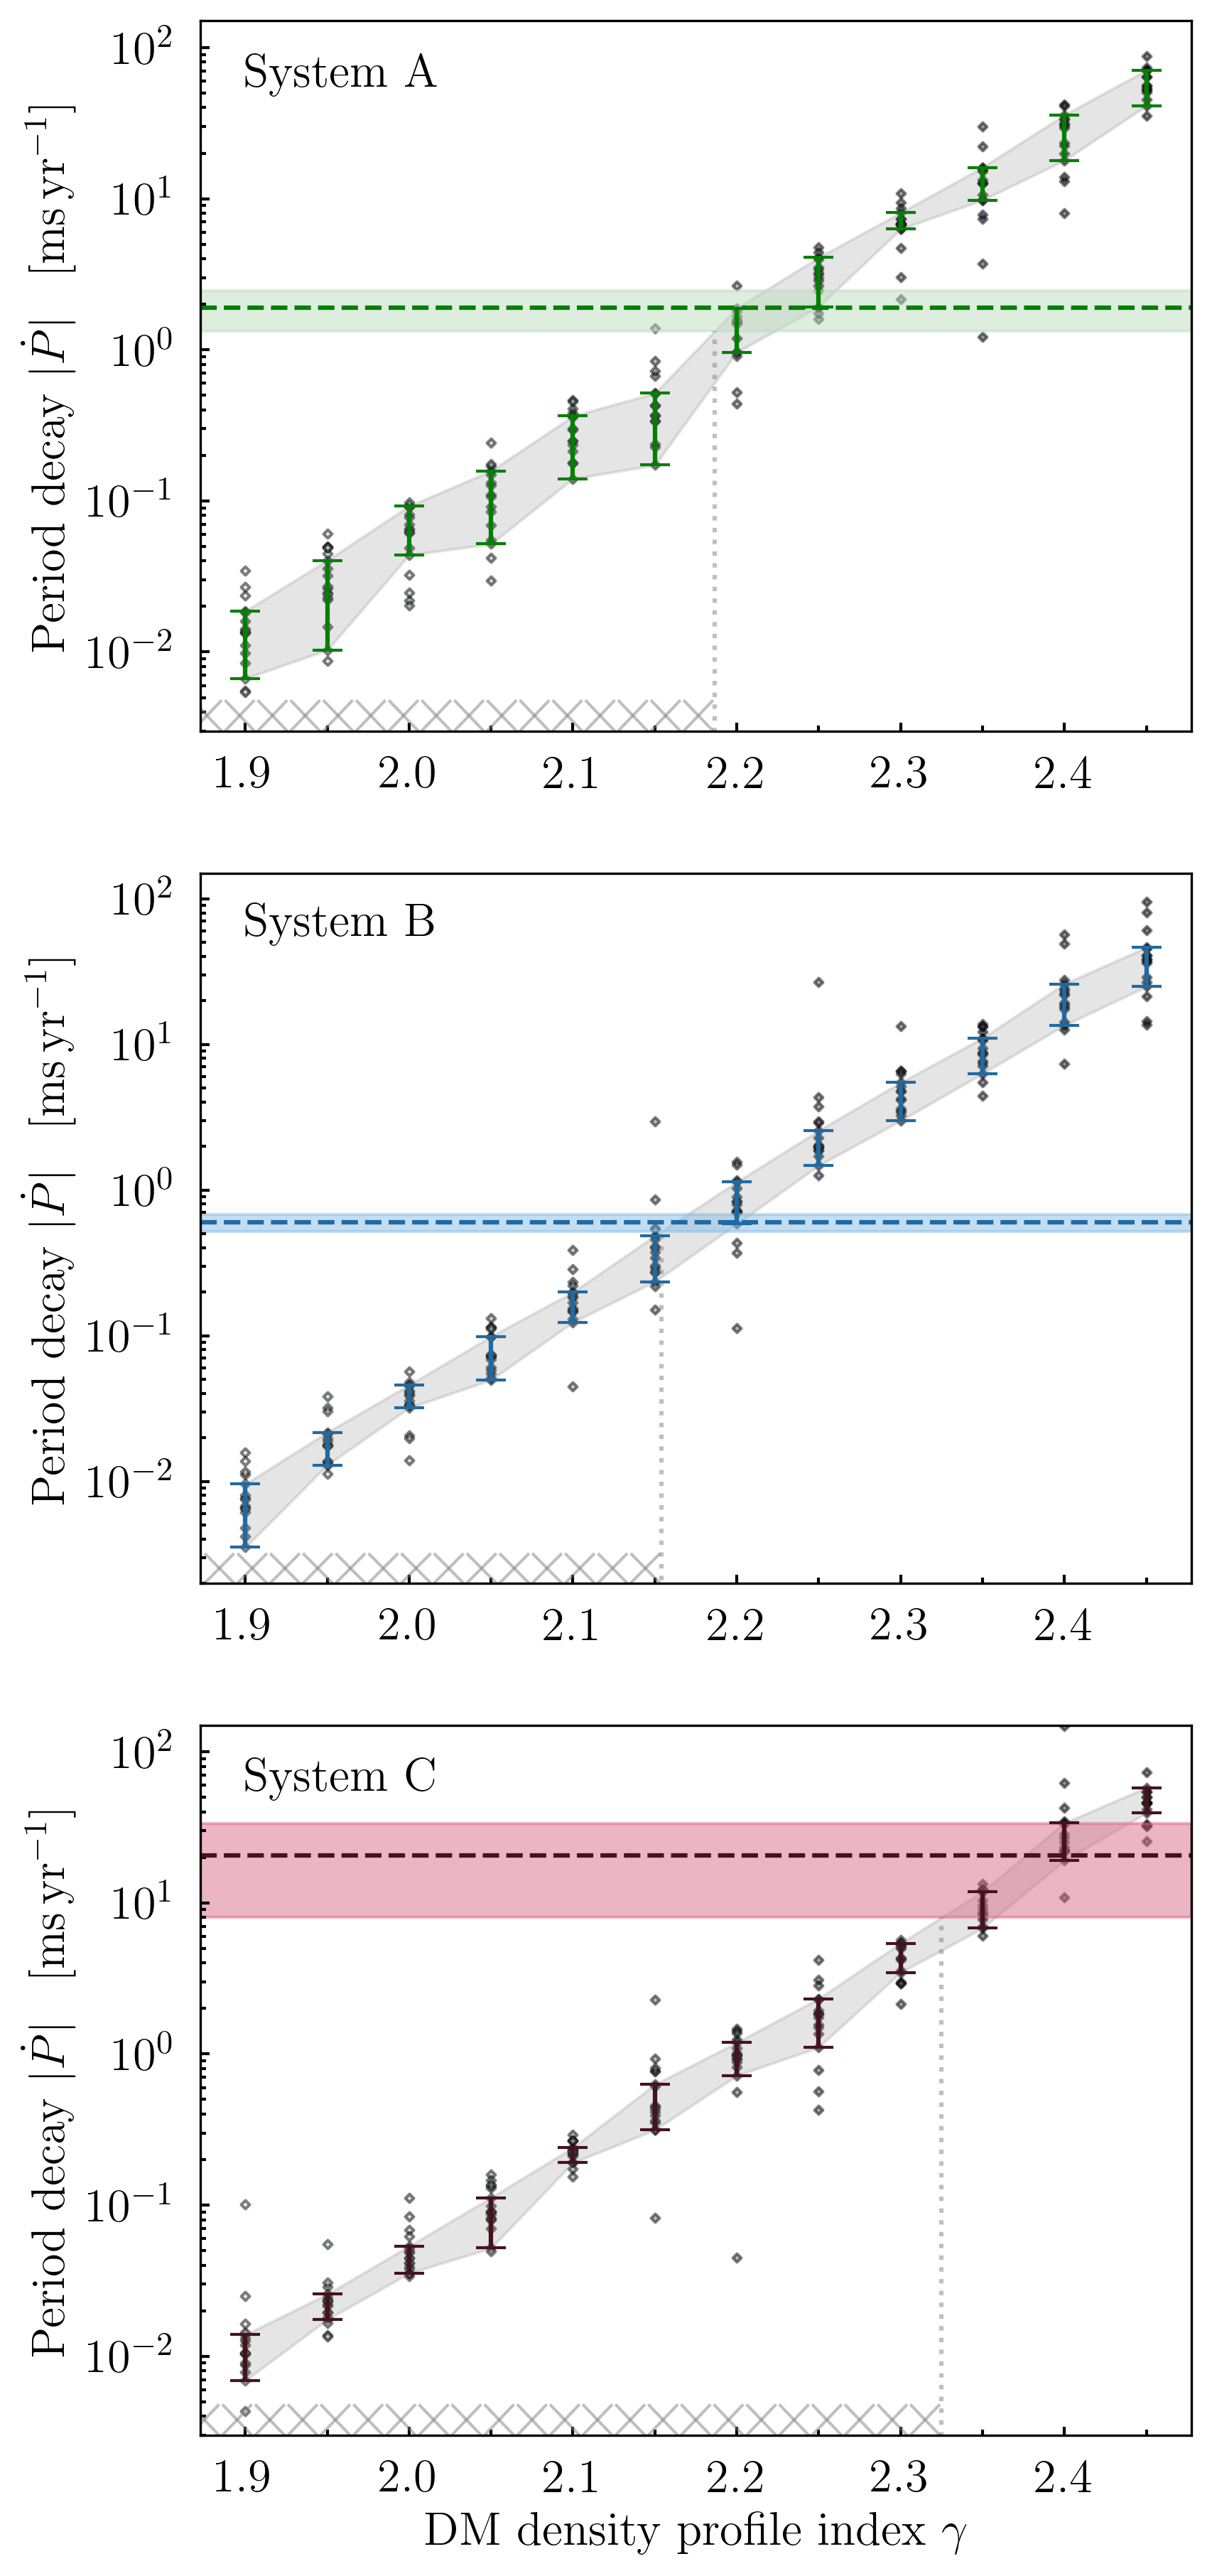

In [69]:
plt.figure(figsize=(10, 6))

# Create figure with two side-by-side subplots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(6, 15),  # 12" width, 5" height
                               sharex=False,             # Share x-axis scale/labels
                               gridspec_kw={'hspace': 0.2})  # Reduce space between plots



cmap = plt.get_cmap('bone')
colors = cmap(np.linspace(0,1, len(gammalist)+2))


def plotstuff(ax,dic):
    # Plot individual points
    
    values=dic["points"]
    means=dic["means"]
    sigmas=dic["sigmas"]
    dTobs=dic["dTobs"]
    dTerr=dic["dTerr"]
    color=dic["color"]
    shade=dic["shade"]
    
    for i, gamma in enumerate(gammalist):       
        mean=-means[i]
        sigma=sigmas[i]
        points= -values[i]

        ax.scatter(gamma*np.ones(len(points)), points, alpha=.5, s=4, marker="D", color=colors[-(i+2)], edgecolor='black')
        # Plot standard deviations as vertical error bars
        ax.errorbar(gamma, mean, yerr=sigma, fmt='none', ecolor=color, capsize=5)
       
    ax.fill_between(gammalist, y1=-(means-sigmas), y2=-(means+sigmas), color='gray',alpha=.2)   
    ax.axhline(dTobs, linestyle='--', color=color)
    ax.axhspan((dTobs-dTerr), (dTobs+dTerr) , alpha=0.5, color=shade)
    
    ax.vlines(dic["g_min_log"], 1e-3, (dTobs-dTerr),  alpha=.5, color="gray", linestyle=":")
   
    ax.set_yscale("log")
    
    plot_excluded_range_semilogy(ax, 1.8, dic["g_min_log"], cross_height_factor=1.6, spacing=0.02, color='gray', alpha=.5, linewidth=1)
    
    



    
ax1.set_ylabel(r" Period decay $|\dot{P}|$ \, $[\mathrm{ms} \, \mathrm{yr}^{-1}]$")
ax2.set_ylabel(r" Period decay $|\dot{P}|$ \, $[\mathrm{ms} \, \mathrm{yr}^{-1}]$")
ax3.set_ylabel(r" Period decay $|\dot{P}|$ \, $[\mathrm{ms} \, \mathrm{yr}^{-1}]$")
ax3.set_xlabel(r'DM density profile index $\gamma$') 

ax1.tick_params(axis='both', which='both', direction='in', length=2, pad=8)
ax2.tick_params(axis='both', which='both', direction='in', length=2)
ax3.tick_params(axis='both', which='both', direction='in', length=2, pad=8)
ax1.tick_params(axis='both', which='major', direction='in', length=3)
ax2.tick_params(axis='both', which='major', direction='in', length=3, pad=8)
ax3.tick_params(axis='both', which='major', direction='in', length=3)

ax1.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax1.xaxis.set_minor_locator(plt.MultipleLocator(.05))
ax2.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax2.xaxis.set_minor_locator(plt.MultipleLocator(.05))
ax3.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax3.xaxis.set_minor_locator(plt.MultipleLocator(.05))


ax1.set_ylim(3e-3, 150)
ax2.set_ylim(2e-3, 150)
ax3.set_ylim(3e-3, 150)


plotstuff(ax1, XTE_dict)
plotstuff(ax2, A0620_dict)
plotstuff(ax3, NM_dict)



ax1.text(1.9, 55, "System A", fontsize=16, color= "k")
ax2.text(1.9, 55, "System B", fontsize=16, color= "k")
ax3.text(1.9, 55, "System C", fontsize=16, color= "k")



plt.savefig('../plots/Pdot_gamma_v2.pdf',transparent=False,bbox_inches='tight')


plt.show()


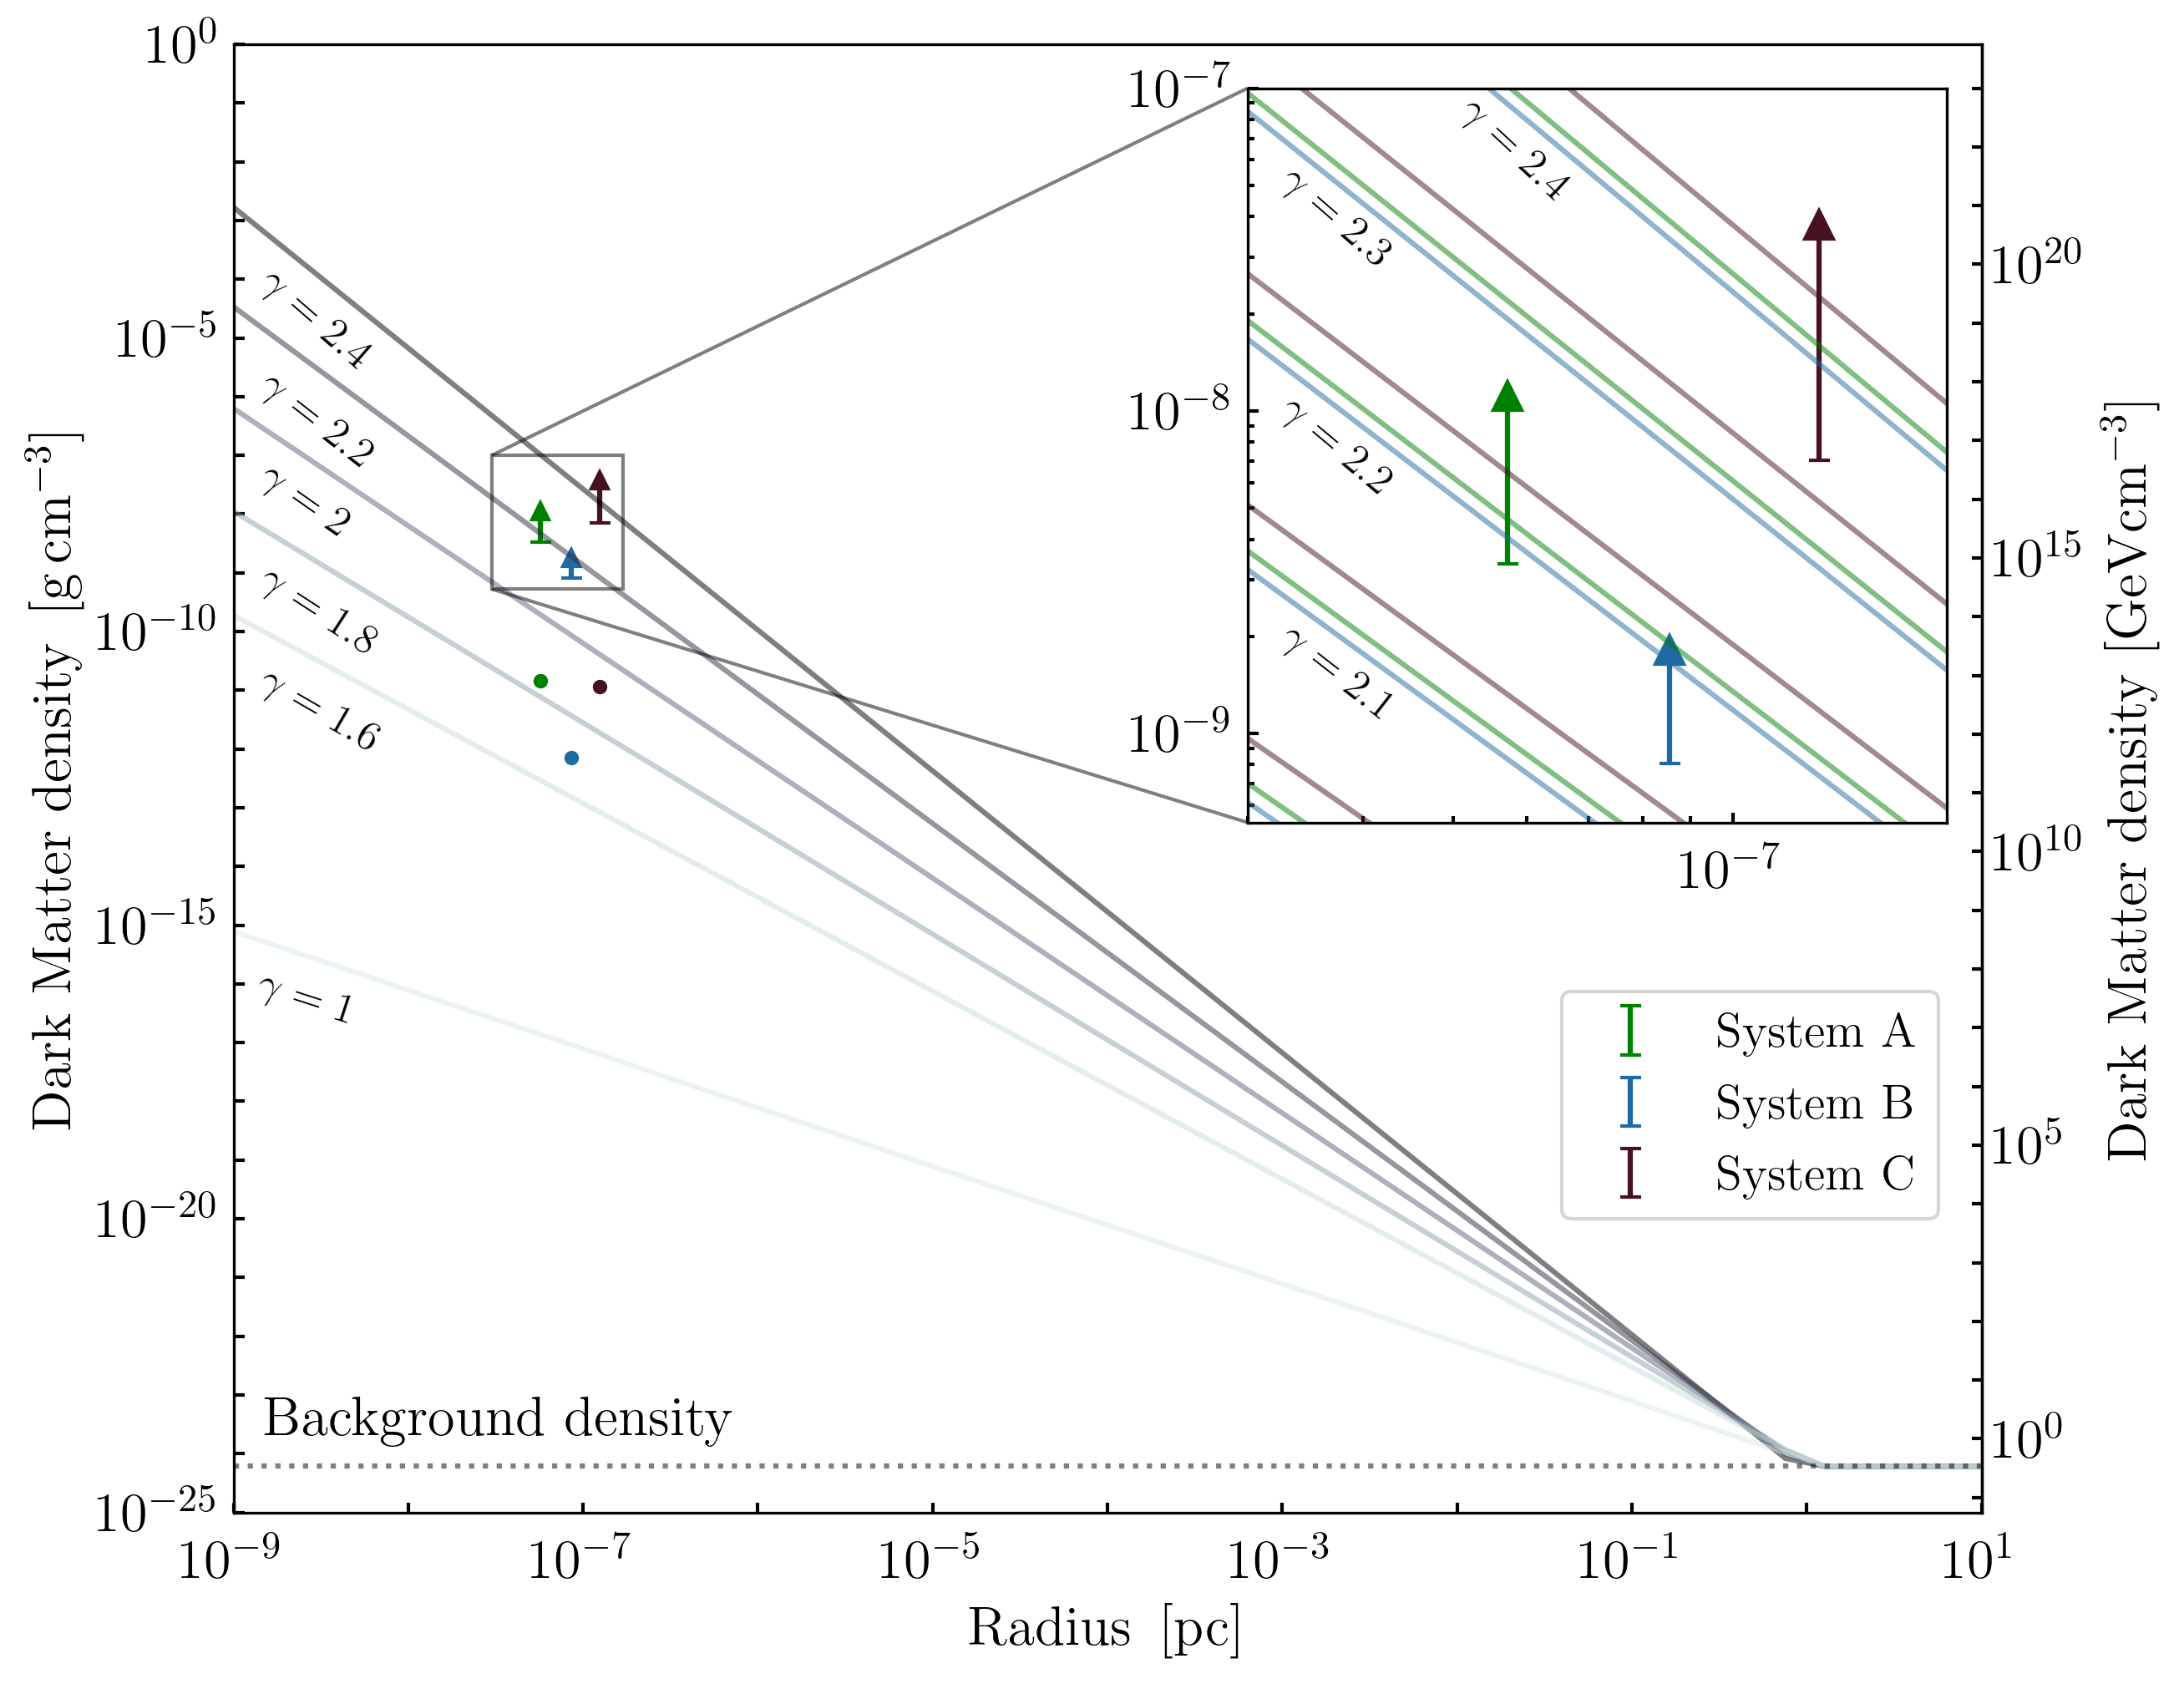

In [92]:
r_vec=np.logspace(-10, 1, 50)*u.pc



# Create figure with two side-by-side subplots
plt.figure(figsize=(9,7)  )


# Customize plot appearance for publication
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'axes.labelsize': 16,
    'axes.titlesize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'figure.dpi': 300,  # High resolution for publications
    'savefig.dpi': 300,
    'figure.autolayout': True
})

#plt.title("Dark Matter density profiles")

gamma_list= np.append(np.linspace(2.4, 1.6, 17), 1)
gamma_list_main=[2.4,2.2,2.,1.8,1.6,1]
gamma_list_inset=[2.4,2.3,2.2,2.10,2,1.9]


cmap = plt.get_cmap('bone')
colors = cmap(np.linspace(0,1,len(gamma_list)+2))

ax_main=plt.gca()

def plot_lines(ax, ga_list):

    for i, ga in enumerate (gamma_list):

        if ga in ga_list:

            rho_vec=compute_rho(r_vec, ga, XTE_dict)
            rho_vec_2=compute_rho(r_vec, ga, A0620_dict)
            rho_vec_3=compute_rho(r_vec, ga, NM_dict)
            rho_bkg=XTE_dict["rho_bkg"]
            
                      
            if ga_list==gamma_list_inset:
                
                ax.loglog(r_vec/u.pc, np.maximum(rho_vec, rho_bkg)/u.g*u.cm**3, alpha=.5, color = XTE_dict["color"])
                ax.loglog(r_vec/u.pc, np.maximum(rho_vec_2, rho_bkg)/u.g*u.cm**3, alpha=.5, color = A0620_dict["color"])
                ax.loglog(r_vec/u.pc, np.maximum(rho_vec_3, rho_bkg)/u.g*u.cm**3, alpha=.5, color = NM_dict["color"])
            else:
                ax.loglog(r_vec/u.pc, np.maximum(rho_vec, rho_bkg)/u.g*u.cm**3, alpha=.5, color = colors[i])



def plot_points(ax, **kwargs):
        
    for dic in dic_list:

        ax.scatter(dic["r_orb"]/u.pc, dic["rho_CH"]/u.g*u.cm**3, s=10,  color =dic["color"])

        rho_min=compute_rho(dic["r_orb"], dic["g_min"], dic)
        rho_max=compute_rho(dic["r_orb"], dic["g_max"], dic)

        rho_mean=(rho_min+rho_max)/2
        sigma=(rho_max-rho_min)/2
        
        
                
        err=ax.errorbar(dic["r_orb"]/u.pc, rho_mean/u.g*u.cm**3, yerr=sigma/u.g*u.cm**3, fmt='none', ecolor=dic["color"], capsize=3, label=dic["name"])
        err[1][1].set_visible(False)
        
        ax.plot(dic["r_orb"]/u.pc, (rho_mean+sigma)/u.g*u.cm**3, marker='^',color =dic["color"], markersize=kwargs.get('ms', 1),
            markeredgecolor=dic["color"], markerfacecolor=dic["color"])

        

plot_points(ax_main, ms=5)
plot_lines(ax_main,gamma_list_main)      

    
plt.axhline(XTE_dict["rho_bkg"]/u.g*u.cm**3, linestyle=dic["linestyle"], alpha=.5, color = "black")
plt.text( 15e-10, 2e-24, r"Background density", fontsize=16)

plt.text(13e-10, 2e-17, f"$\gamma=1$", fontsize=12, rotation=-18)
plt.text(13e-10, 9e-13, f"$\gamma=1.6$", fontsize=12, rotation=-30)
plt.text(13e-10, 4e-11, f"$\gamma=1.8$", fontsize=12, rotation=-33)
plt.text(13e-10, 4e-9, f"$\gamma=2$", fontsize=12, rotation=-35)
plt.text(13e-10, 6e-8, f"$\gamma=2.2$", fontsize=12, rotation=-38)
plt.text(13e-10, 3e-6, f"$\gamma=2.4$", fontsize=12, rotation=-41)


ax_inset = ax_main.inset_axes([0.58, 0.47, 0.4, 0.5]) 

ax_inset.set_xlim(30e-9, 17e-8)
ax_inset.set_ylim(53e-11,1e-7)
           
mark_inset(ax_main, ax_inset, loc1=3, loc2=2, fc="none", ec="0",color='b',alpha=.5,lw=1,zorder=10)

plot_points(ax_inset, ms=8) 
plot_lines(ax_inset, gamma_list_inset)  

from matplotlib import ticker
#ax_inset.xaxis.set_major_locator(ticker.NullLocator()) 
#ax_inset.xaxis.set_minor_locator(ticker.NullLocator())
ax_inset.tick_params(axis='y', which='major', direction='in', length=3)
ax_inset.tick_params(axis='y', which='minor', direction='in', length=2)
ax_inset.tick_params(axis='x', which='major', direction='in', length=3, pad=8)
ax_inset.tick_params(axis='x', which='minor', direction='in', length=2)


#Create secondary axis with converted units
secax = ax_main.secondary_yaxis(
    'right',
    functions=(
        lambda g: g * u.g/u.GeV,  # Convert g/cm³ → GeV/c²/cm³
        lambda GeV: GeV *u.GeV/u.g  # Inverse
    )
)

secax.set_ylabel(r'Dark Matter density [$\mathrm{GeV}\mathrm{cm}^{-3}$]')

ax_main.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=100)) 
ax_main.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=100)) 
secax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=100)) 


# 2. Custom formatter for labels (only every 5 decades)
def format_decade_label_5(value, pos=None):
    exponent = int(np.log10(value))
    if exponent % 5 == 0:  # Only label every 5th decade
        return r'$10^{{{}}}$'.format(exponent)
    return ''  # Empty label for other decades

# 2. Custom formatter for labels (only every 2 decades)
def format_decade_label_2(value, pos=None):
    exponent = int(np.log10(value))
    if (exponent+1) % 2 == 0:  # Only label every 2th decade
        return r'$10^{{{}}}$'.format(exponent)
    return ''  # Empty label for other decades

# Apply formatters
ax_main.xaxis.set_major_formatter(ticker.FuncFormatter(format_decade_label_2))
ax_main.yaxis.set_major_formatter(ticker.FuncFormatter(format_decade_label_5))
secax.yaxis.set_major_formatter(ticker.FuncFormatter(format_decade_label_5))
ax_inset.xaxis.set_major_formatter(ticker.FuncFormatter(format_decade_label_2))
ax_inset.xaxis.set_minor_formatter(ticker.FuncFormatter(lambda y, _: f''))

ax_main.tick_params(axis='both', which='both', direction='in', length=3)
ax_main.tick_params(axis='x', which='major', pad=8)   # Increase pad as needed
secax.tick_params(axis='both', which='both', direction='in', length=3)

ax_main.legend(loc= (.76,.2), fontsize=14)

ax_inset.text(50e-9, 45e-9, f"$\gamma=2.4$", fontsize=12, rotation=-43)
ax_inset.text(32e-9, 28e-9, f"$\gamma=2.3$", fontsize=12, rotation=-41)
ax_inset.text(32e-9, 55e-10, f"$\gamma=2.2$", fontsize=12, rotation=-40)
ax_inset.text(32e-9, 11e-10, f"$\gamma=2.1$", fontsize=12, rotation=-38)

plt.ylim(1e-25, 1)
plt.xlim(1e-9, 10)

plt.xlabel(r"Radius  $\,  [\mathrm{pc}]$")
plt.ylabel(r"Dark Matter density $\, [\mathrm{g} \, \mathrm{cm}^{-3}]$")

#plt.grid(True, alpha=.1)

plt.savefig('../plots/Profiles.pdf',transparent=False,bbox_inches='tight')

plt.show()